# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Luis David Santoyo Romero  
**Grupo:** 511  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```


## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

print("Primeras cinco filas:")
display(df.head())
print("Dimensiones:", df.shape)
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)

print("\nResumen estadístico de columnas numéricas:")
display(df.describe().T)

print("Valores de payment_type (incluye nulos):")
print(df["payment_type"].value_counts(dropna=False).sort_index())

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 20)

Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_con

,count,mean,std,min,25%,50%,75%,max
VendorID,2427612.0,1.888167,0.808684,1.000000,2.000000,2.000000,2.000000,7.000000
passenger_count,2415489.0,1.296144,1.881923,-5.000000,1.000000,1.000000,1.000000,100.000000
trip_distance,2415470.0,3.300702,5.167909,-99.987634,0.990000,1.700000,3.360000,1686.490000
RatecodeID,2415474.0,4.229419,17.202198,1.000000,1.000000,1.000000,1.000000,99.000000
PULocationID,2415487.0,164.139170,62.853858,1.000000,132.000000,161.000000,232.000000,265.000000
DOLocationID,2415475.0,163.223620,69.256125,1.000000,113.000000,162.000000,234.000000,265.000000
payment_type,2415487.0,1.174306,0.459415,1.000000,1.000000,1.000000,1.000000,4.000000
fare_amount,2415488.0,38.525671,542.376418,-1849.600000,9.300000,13.500000,21.900000,19995.589825
extra,2415487.0,1.567837,1.906552,-7.500000,0.000000,1.000000,2.500000,23.250000
mta_tax,2415462.0,0.484991,0.101868,-0.500000,0.500000,0.500000,0.500000,11.500000


Valores de payment_type (incluye nulos):
payment_type
1.0    2051983
2.0     329533
3.0      10413
4.0      23558
NaN      12125
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()

print("Dimensiones antes de limpiar:", df_limpio.shape)
print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())
print("\nRegistros duplicados:", df_limpio.duplicated().sum())

df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].reset_index(drop=True)

print("\nDimensiones después de limpiar:", df_limpio.shape)
print("Registros eliminados:", len(df) - len(df_limpio))

Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna:


VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64



Registros duplicados: 11961



Dimensiones después de limpiar: (2096600, 20)
Registros eliminados: 331012


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [ ]:
# payment_type == 2 (cash)
print(df_limpio["payment_type"].value_counts().sort_index())

df_cash = df_limpio[df_limpio["payment_type"] == 2].reset_index(drop=True)
X = df_cash[["passenger_count", "trip_distance"]]
print("Viajes pagados en efectivo:", len(df_cash))
print("Estadísticas descriptivas de X:")
display(X.describe())

payment_type
Credit card    1799462
Cash            282085
Dispute           9753
No charge         5300
Name: count, dtype: int64

Viajes pagados en efectivo: 282085

Estadísticas descriptivas de X:


,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,1.343882,3.842165
std,0.759067,6.214391
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)

print("Resumen de X_log (log1p):")
display(X_log.describe())

print("Resumen de X_escalado (estandarizado):")
display(pd.DataFrame(X_escalado, columns=X.columns).describe().round(4))

Resumen de X_log (log1p):


,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,0.814772,1.225454
std,0.250268,0.763298
min,0.693147,0.009950
25%,0.693147,0.652325
50%,0.693147,0.993252
75%,0.693147,1.680828
max,1.945910,7.430997


Resumen de X_escalado (estandarizado):


,passenger_count,trip_distance
count,282085.0000,282085.0000
mean,-0.0000,0.0000
std,1.0000,1.0000
min,-0.4860,-1.5924
25%,-0.4860,-0.7509
50%,-0.4860,-0.3042
75%,-0.4860,0.5966
max,4.5197,8.1299


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,324581.939870,0.550292
1,3,160363.188416,0.611688
2,4,115075.583100,0.620217
3,5,86895.898261,0.624864
4,6,61144.889106,0.561741


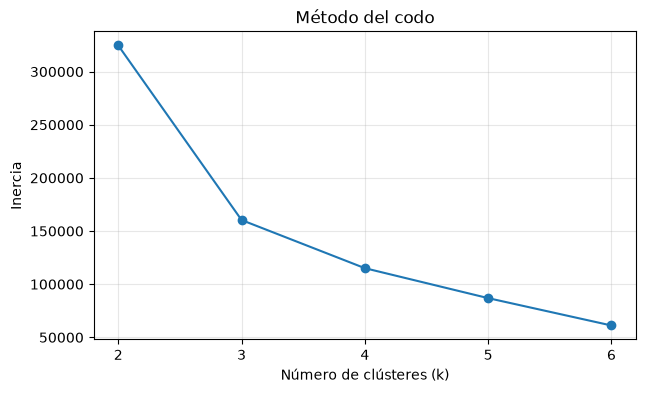

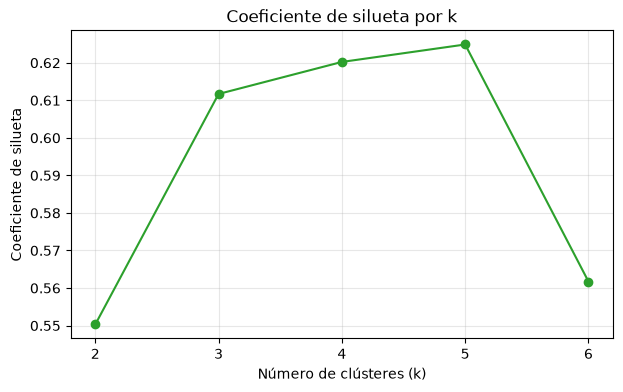

In [5]:
ks = range(2, 7)
inercias = []
siluetas = []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = km.fit_predict(X_escalado)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42))

tabla_k = pd.DataFrame({"k": list(ks), "Inercia": inercias, "Silueta": siluetas})
display(tabla_k)

plt.figure(figsize=(7, 4))
plt.plot(tabla_k["k"], tabla_k["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(tabla_k["k"], tabla_k["Silueta"], marker="o", color="tab:green")
plt.title("Coeficiente de silueta por k")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

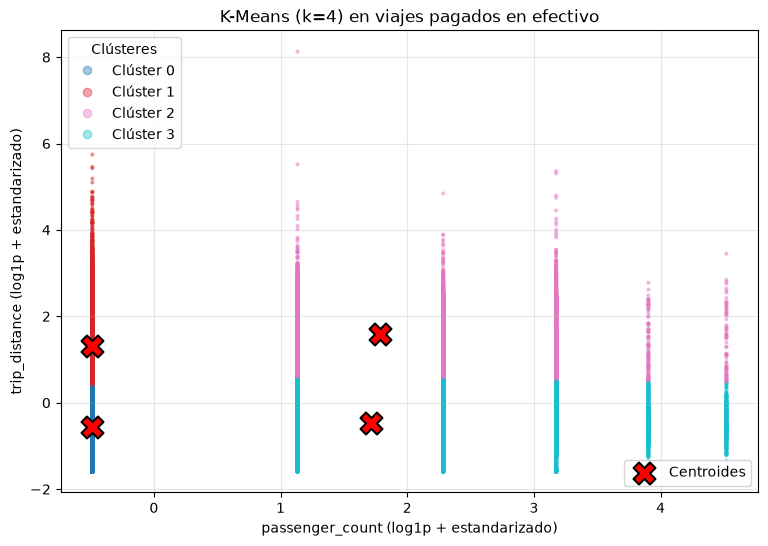

In [6]:
K_FINAL = 4

modelo = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
etiquetas = modelo.fit_predict(X_escalado)
centroides = modelo.cluster_centers_

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_escalado[:, 0], X_escalado[:, 1], c=etiquetas, cmap="tab10", s=4, alpha=0.4)
plt.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=250, c="red", edgecolors="black", linewidths=1.5, label="Centroides")
plt.title(f"K-Means (k={K_FINAL}) en viajes pagados en efectivo")
plt.xlabel("passenger_count (log1p + estandarizado)")
plt.ylabel("trip_distance (log1p + estandarizado)")
handles, _ = scatter.legend_elements()
leyenda_cl = plt.legend(handles, [f"Clúster {i}" for i in range(K_FINAL)], title="Clústeres", loc="upper left")
plt.gca().add_artist(leyenda_cl)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

estadisticos = df_resultado.groupby("cluster").agg(
    viajes=("cluster", "size"),
    pasajeros_media=("passenger_count", "mean"),
    pasajeros_mediana=("passenger_count", "median"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
).round(2)

display(estadisticos)

,viajes,pasajeros_media,pasajeros_mediana,distancia_media_millas,distancia_mediana_millas
cluster,,,,,
0,160372,1.00,1.0,1.36,1.20
1,59946,1.00,1.0,9.55,7.96
2,18849,2.62,2.0,12.08,10.37
3,42918,2.55,2.0,1.53,1.30


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** 
Elegí **k = 4**. La inercia siempre baja al subir k, pero la caída fuerte termina entre k=3 y k=4 (324,582 → 160,363 → 115,076 → 86,896), así que el codo está alrededor de 3–4. La silueta sube hasta 0.620 en k=4 y 0.625 en k=5, y cae a 0.562 en k=6. Entre k=4 y k=5 casi no mejora (0.005) y k=5 solo divide en subgrupos que casi no se distinguen. Con k=4 los grupos quedan claros y fáciles de interpretar.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

- Clúster 0 – Solo, viaje corto: 160,372 viajes. 1 pasajero (media y mediana); distancia media 1.36 mi y mediana 1.20 mi.
- Clúster 1 – Solo, viaje largo: 59,946 viajes. 1 pasajero; distancia media 9.55 mi y mediana 7.96 mi.
- Clúster 2 – Grupo, viaje largo: 18,849 viajes. Media de 2.62 pasajeros (mediana 2); distancia media 12.08 mi y mediana 10.37 mi.
- Clúster 3 – Grupo, viaje corto: 42,918 viajes. Media de 2.55 pasajeros (mediana 2); distancia media 1.53 mi y mediana 1.30 mi.

**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:** 
Los grupos con menos pasajeros (clústeres 0 y 1, 1.00 en promedio) son la mayoría de los viajes: 220,318 contra 61,767 de los grupos con más pasajeros (clústeres 2 y 3, ~2.6). La distancia cambia poco por el número de pasajeros: entre los viajes cortos son 1.36 mi contra 1.53 mi, y entre los largos 9.55 mi contra 12.08 mi. Los grupos con más pasajeros viajan un poco más lejos, pero la diferencia importante es corto contra largo.

**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:** 
Con varios pasajeros hay viajes cortos (clúster 3, mediana de 1.30 mi) y largos (clúster 2, mediana de 10.37 mi). Además, quien viaja solo también hace viajes largos (clúster 1, mediana de 7.96 mi), mucho más que el clúster 3 aunque este tenga más pasajeros. La distancia depende del tipo de viaje, no de cuántas personas van, y la mayoría de los viajes son cortos.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**